In [947]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import mnist

In [899]:
RANDOM_STATE = 42
BIN_THRESHOLD = 127

BIN_NOISE_P = 0.15
GRAY_NOISE_LEVEL = 3

K_VALUES = [1, 3, 5, 7, 9, 15, 25, 35]

In [900]:
(x_train_full, y_train_full), (x_test_full, y_test_full) = mnist.load_data()

len(x_train_full), len(x_test_full)

(60000, 10000)

In [901]:
for i in range(10):
    print(f"{i}: {int(100 * (y_test_full == i).astype(int).sum() / len(y_test_full))}%")

0: 9%
1: 11%
2: 10%
3: 10%
4: 9%
5: 8%
6: 9%
7: 10%
8: 9%
9: 10%


In [902]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    x_test_full, y_test_full, test_size=0.2, random_state=RANDOM_STATE, shuffle=True, stratify=y_test_full
)

len(X_train), len(X_test)

(8000, 2000)

In [903]:
for i in range(10):
    print(f"{i}: {int(100 * (y_train == i).astype(int).sum() / len(y_train))}%")

0: 9%
1: 11%
2: 10%
3: 10%
4: 9%
5: 8%
6: 9%
7: 10%
8: 9%
9: 10%


In [904]:
for i in range(10):
    print(f"{i}: {int(100 * (y_test == i).astype(int).sum() / len(y_test))}%")

0: 9%
1: 11%
2: 10%
3: 10%
4: 9%
5: 8%
6: 9%
7: 10%
8: 9%
9: 10%


In [905]:
def preview_dataset(image_dataset):
    plt.figure(figsize=(12, 8))

    for i in range(10):
        plt.subplot(4, 5, i + 1)
        plt.imshow(image_dataset[i], cmap="gray")
        plt.axis("off")

In [906]:
def to_binary(images):
    return (images >= BIN_THRESHOLD).astype(np.float32)

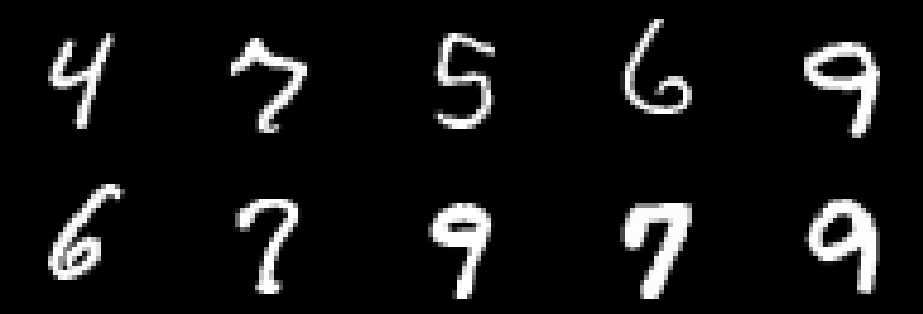

In [907]:
preview_dataset(X_train)

In [908]:
X_train_bin = to_binary(X_train)
X_test_bin = to_binary(X_test)

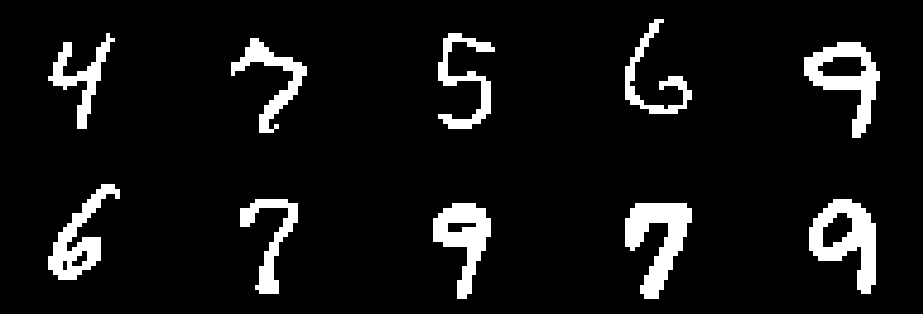

In [909]:
preview_dataset(X_train_bin)

In [910]:
def uniform_noise_bin(image, p: float):
    mask = np.random.random(image.shape) < p

    noisy_image = image.copy()
    noisy_image[mask] = 1 - noisy_image[mask]

    return noisy_image

In [911]:
def uniform_noise_gray(image, noise_level: float):
    direction = np.random.choice(
        [-1, 1],
        size=image.shape
    )

    change = (
        np.random.random(image.shape)
        * noise_level
        * (image + 64)
    )

    noisy_image = image + direction * change
    return np.clip(noisy_image, 0, 255)


In [912]:
def nonuniform_noise_bin(image, p: float):
    noisy_image = image.copy()

    # image.shape = (8000, 28, 28)
    h, w = image.shape[1:]
    middle = w // 2

    mask = np.random.random(image.shape) < p
    mask[:, :middle] = 0

    noisy_image[mask] = 1 - noisy_image[mask]
    return noisy_image


In [913]:
def nonuniform_noise_gray(image, noise_level: float):
    direction = np.random.choice(
        [-1, 1],
        size=image.shape
    )

    # change:
    # * white:
    change = (
            np.random.random(image.shape)
            * noise_level
            * (image + 64)
    )

    # image.shape = (8000, 28, 28)
    h, w = image.shape[1:]
    middle = w // 2
    change[:, :middle] = 0

    noisy_image = image + direction * change
    return np.clip(noisy_image, 0, 255)


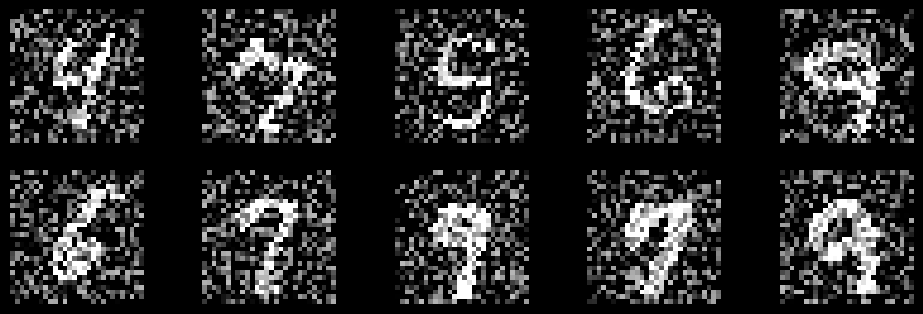

In [914]:
noise_level=GRAY_NOISE_LEVEL
X_train_uniform_noise_gray = uniform_noise_gray(X_train, noise_level)
X_test_uniform_noise_gray = uniform_noise_gray(X_test, noise_level)
preview_dataset(X_train_uniform_noise_gray)

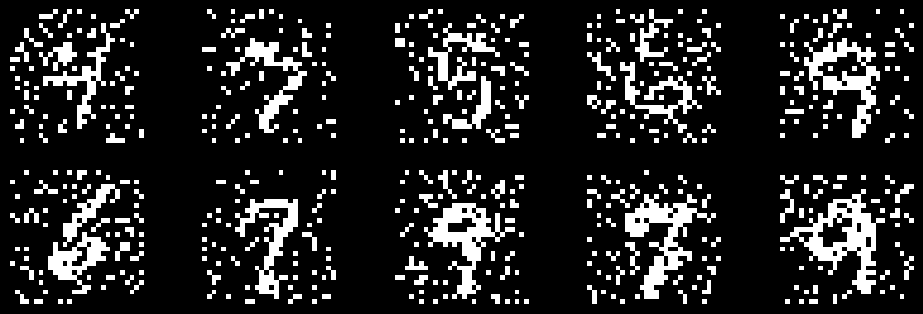

In [915]:
p = BIN_NOISE_P
X_train_uniform_noise_bin = uniform_noise_bin(X_train_bin, p=p)
X_test_uniform_noise_bin = uniform_noise_bin(X_test, p=p)

preview_dataset(X_train_uniform_noise_bin)

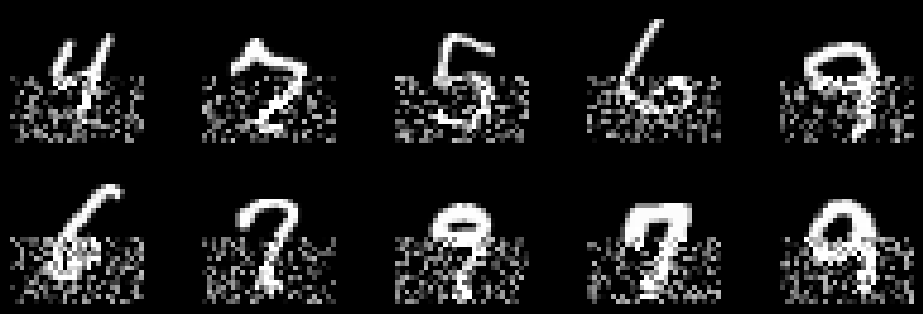

In [916]:
noise_level=GRAY_NOISE_LEVEL
X_train_nonuniform_noise_gray = nonuniform_noise_gray(X_train, noise_level)
X_test_nonuniform_noise_gray = nonuniform_noise_gray(X_test, noise_level)
preview_dataset(X_train_nonuniform_noise_gray)

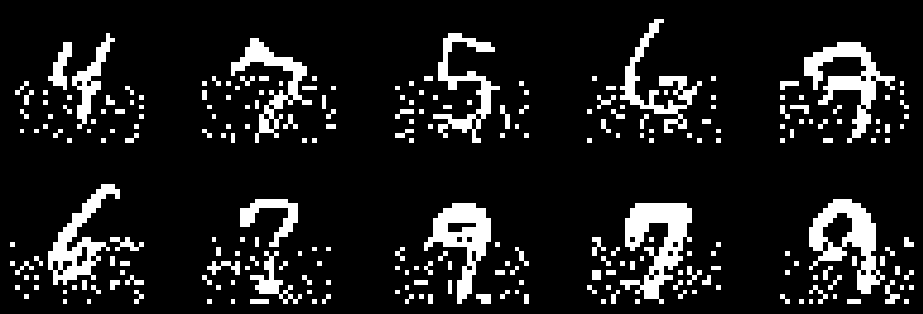

In [917]:
p = BIN_NOISE_P
X_train_nonuniform_noise_bin = nonuniform_noise_bin(X_train_bin, p=p)
X_test_nonuniform_noise_bin = nonuniform_noise_bin(X_test, p=p)

preview_dataset(X_train_nonuniform_noise_bin)

In [918]:
class KNNClassifier:
    def __init__(self, k=3, metric="euclidean"):
        self.__k = k
        self.__metric = metric
        self.__X_train = None
        self.__y_train = None
        self.__max = 1

    def fit(self, X, y):
        self.__max = X.max()
        self.__X_train = X.reshape(X.shape[0], -1) / self.__max
        self.__y_train = y

    def __predict_one(self, x):
        x = x.ravel()

        if self.__metric == "euclidean":
            distances = np.sum((self.__X_train - x) ** 2, axis=1)
        elif self.__metric == "manhattan":
            distances = np.sum(np.abs(self.__X_train - x), axis=1)
        elif self.__metric == "chebyshev":
            distances = np.max(np.abs(self.__X_train - x), axis=1)
        else:
            raise ValueError(f"Unknown metric: {self.__metric}")

        nearest_idx = np.argpartition(distances, self.__k - 1)[:self.__k]

        nearest_labels = self.__y_train[nearest_idx]

        return np.bincount(nearest_labels).argmax()

    def predict(self, X):
        X = X / self.__max
        return np.array(list(map(self.__predict_one, X)))

In [919]:
data = {}

In [920]:
from sklearn.metrics import f1_score

def test_dataset(X_train_current, X_test_current, y_train_current, y_test_current, label):
    data[label] = []

    distances = ["euclidean", "manhattan", "chebyshev"]

    print("-" * 16, f"TESTING {label}", "-" * 16)
    print(f"{'k':<8}{'metric':<16}{'f1_min':<12}{'f1_avg':<12}{'f1_max':<12}")

    for k in K_VALUES:
        for d in distances:
            clf = KNNClassifier(k=k, metric=d)
            clf.fit(X_train_current, y_train_current)
            y_pred = clf.predict(X_test_current)
            f1 = f1_score(y_test_current, y_pred, average=None)
            data[label].append((k, d, f1.min(), f1.mean(), f1.max()))
            print(f"{k:<8}{d:<16}{round(f1.min(), 2):<12}{round(f1.mean(), 2):<12}{round(f1.max(), 2):<12}")

In [921]:
test_dataset(X_train, X_test, y_train, y_test, label="Gray without noise")

---------------- TESTING Gray without noise ----------------
k       metric          f1_min      f1_avg      f1_max      
1       euclidean       0.93        0.95        0.99        
1       manhattan       0.92        0.94        0.98        
1       chebyshev       0.59        0.72        0.91        
3       euclidean       0.93        0.95        0.98        
3       manhattan       0.91        0.94        0.98        
3       chebyshev       0.54        0.68        0.86        
5       euclidean       0.91        0.95        0.98        
5       manhattan       0.91        0.94        0.98        
5       chebyshev       0.54        0.69        0.87        
7       euclidean       0.92        0.94        0.97        
7       manhattan       0.91        0.94        0.97        
7       chebyshev       0.52        0.68        0.87        
9       euclidean       0.9         0.94        0.97        
9       manhattan       0.91        0.94        0.97        
9       chebyshev       

In [922]:
test_dataset(X_train_bin, X_test_bin, y_train, y_test, label="Binary without noise")

---------------- TESTING Binary without noise ----------------
k       metric          f1_min      f1_avg      f1_max      
1       euclidean       0.9         0.94        0.98        
1       manhattan       0.9         0.94        0.98        
1       chebyshev       0.0         0.02        0.18        
3       euclidean       0.9         0.93        0.97        
3       manhattan       0.9         0.93        0.97        
3       chebyshev       0.0         0.02        0.18        
5       euclidean       0.9         0.93        0.97        
5       manhattan       0.9         0.93        0.97        
5       chebyshev       0.0         0.02        0.18        
7       euclidean       0.9         0.93        0.98        
7       manhattan       0.9         0.93        0.98        
7       chebyshev       0.0         0.02        0.19        
9       euclidean       0.9         0.93        0.97        
9       manhattan       0.9         0.93        0.97        
9       chebyshev     

In [923]:
test_dataset(X_train_uniform_noise_gray, X_test_uniform_noise_gray, y_train, y_test, label="Gray with uniform noise")

---------------- TESTING Gray with uniform noise ----------------
k       metric          f1_min      f1_avg      f1_max      
1       euclidean       0.73        0.82        0.93        
1       manhattan       0.7         0.79        0.94        
1       chebyshev       0.0         0.02        0.18        
3       euclidean       0.76        0.84        0.94        
3       manhattan       0.72        0.81        0.93        
3       chebyshev       0.0         0.02        0.18        
5       euclidean       0.76        0.86        0.95        
5       manhattan       0.73        0.82        0.95        
5       chebyshev       0.0         0.02        0.18        
7       euclidean       0.76        0.85        0.94        
7       manhattan       0.72        0.83        0.95        
7       chebyshev       0.0         0.02        0.19        
9       euclidean       0.76        0.85        0.94        
9       manhattan       0.71        0.83        0.94        
9       chebyshev  

In [924]:
test_dataset(X_train_nonuniform_noise_gray, X_test_nonuniform_noise_gray, y_train, y_test, label="Gray with non-uniform noise")

---------------- TESTING Gray with non-uniform noise ----------------
k       metric          f1_min      f1_avg      f1_max      
1       euclidean       0.87        0.92        0.97        
1       manhattan       0.85        0.91        0.97        
1       chebyshev       0.0         0.09        0.59        
3       euclidean       0.87        0.92        0.96        
3       manhattan       0.85        0.91        0.96        
3       chebyshev       0.0         0.09        0.59        
5       euclidean       0.89        0.92        0.97        
5       manhattan       0.86        0.92        0.97        
5       chebyshev       0.0         0.08        0.58        
7       euclidean       0.87        0.92        0.97        
7       manhattan       0.87        0.92        0.97        
7       chebyshev       0.0         0.06        0.42        
9       euclidean       0.88        0.92        0.97        
9       manhattan       0.87        0.91        0.97        
9       chebysh

In [925]:
test_dataset(X_train_uniform_noise_bin, X_test_uniform_noise_bin, y_train, y_test, label="Bin with uniform noise")

---------------- TESTING Bin with uniform noise ----------------
k       metric          f1_min      f1_avg      f1_max      
1       euclidean       0.41        0.69        0.9         
1       manhattan       0.74        0.85        0.95        
1       chebyshev       0.07        0.16        0.21        
3       euclidean       0.34        0.69        0.92        
3       manhattan       0.81        0.88        0.95        
3       chebyshev       0.04        0.16        0.28        
5       euclidean       0.42        0.73        0.94        
5       manhattan       0.83        0.89        0.95        
5       chebyshev       0.04        0.18        0.24        
7       euclidean       0.37        0.72        0.96        
7       manhattan       0.82        0.89        0.95        
7       chebyshev       0.04        0.18        0.29        
9       euclidean       0.36        0.72        0.95        
9       manhattan       0.84        0.9         0.95        
9       chebyshev   

In [926]:
test_dataset(X_train_nonuniform_noise_bin, X_test_nonuniform_noise_bin, y_train, y_test, label="Bin with non-uniform noise")

---------------- TESTING Bin with non-uniform noise ----------------
k       metric          f1_min      f1_avg      f1_max      
1       euclidean       0.47        0.7         0.89        
1       manhattan       0.83        0.9         0.96        
1       chebyshev       0.12        0.2         0.28        
3       euclidean       0.47        0.7         0.92        
3       manhattan       0.87        0.92        0.96        
3       chebyshev       0.09        0.18        0.29        
5       euclidean       0.52        0.74        0.96        
5       manhattan       0.88        0.92        0.97        
5       chebyshev       0.12        0.2         0.3         
7       euclidean       0.55        0.75        0.96        
7       manhattan       0.89        0.93        0.96        
7       chebyshev       0.08        0.2         0.3         
9       euclidean       0.58        0.77        0.97        
9       manhattan       0.88        0.93        0.96        
9       chebyshe

In [937]:
json_data = []

for label in data:
    for k, metric, f1_min, f1_avg, f1_max, in data[label]:
        image_type = ""
        if "Gray" in label:
            image_type = "gray"
        if "Bin" in label:
            image_type = "bin"

        noise_type = ""
        if "non-uniform" in label:
            noise_type = "non-uniform"
        elif "uniform" in label:
            noise_type = "uniform"

        json_data.append({
            "k": k,
            "metric": metric,
            "f1_min": float(f1_min),
            "f1_avg": float(f1_avg),
            "f1_max": float(f1_max),
            "type": image_type,
            "noise": noise_type
        })

In [946]:
import json
with open("data.json", "w") as f:
    json.dump(json_data, f)

In [999]:
plt.style.use("dark_background")
plt.rcParams.update({
    "font.size": 18,
    "axes.titlesize": 18,
    "axes.labelsize": 14,
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
    "legend.fontsize": 13,
    "figure.titlesize": 18,
})

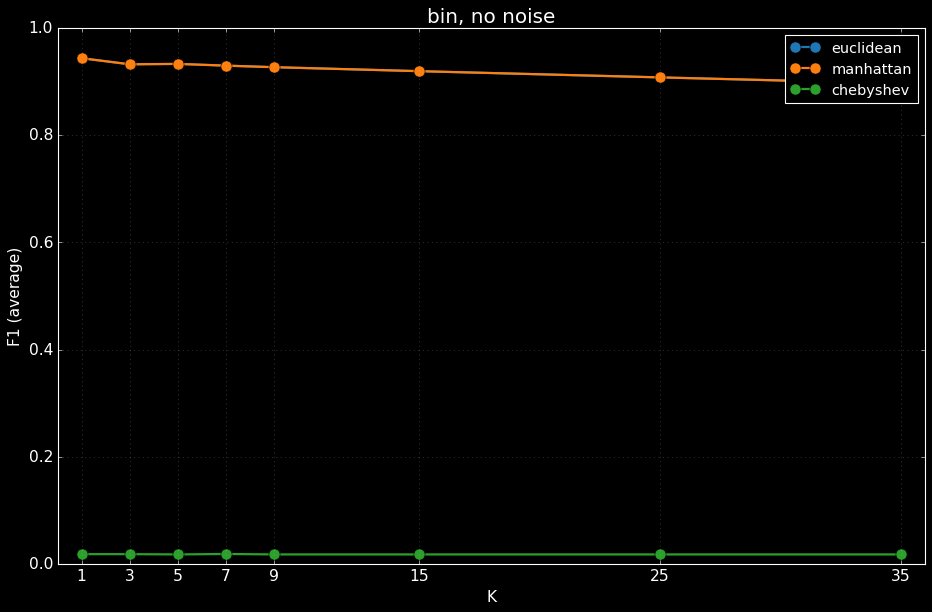

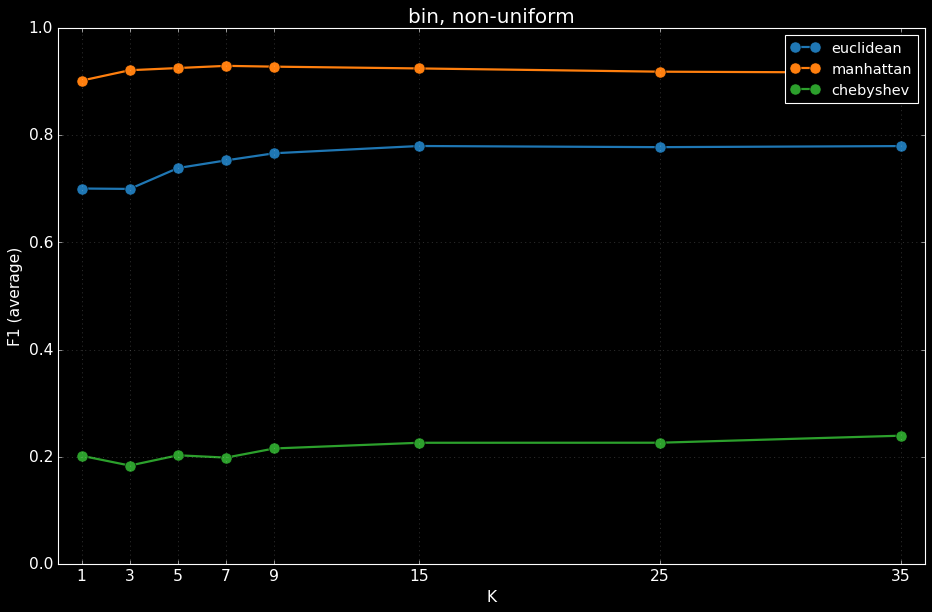

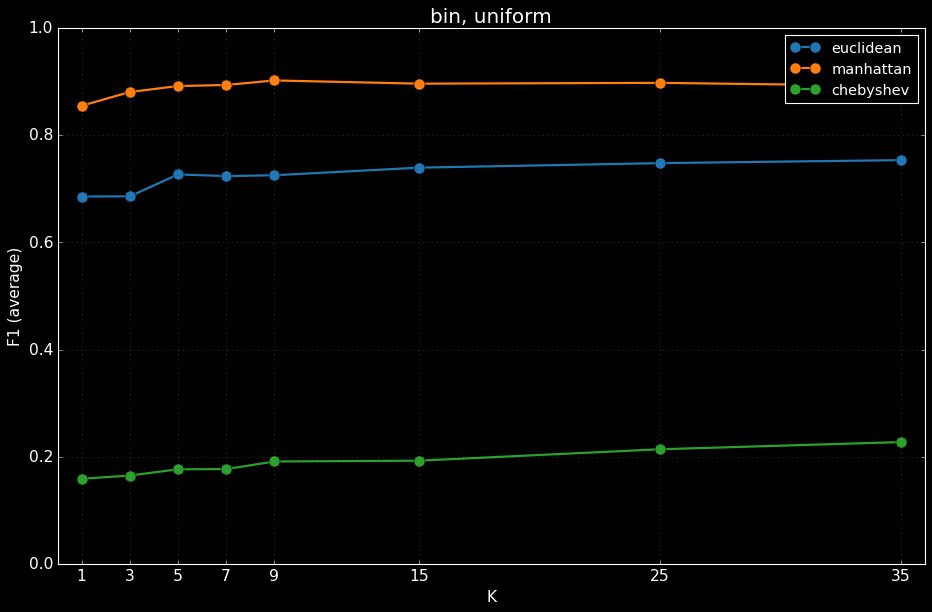

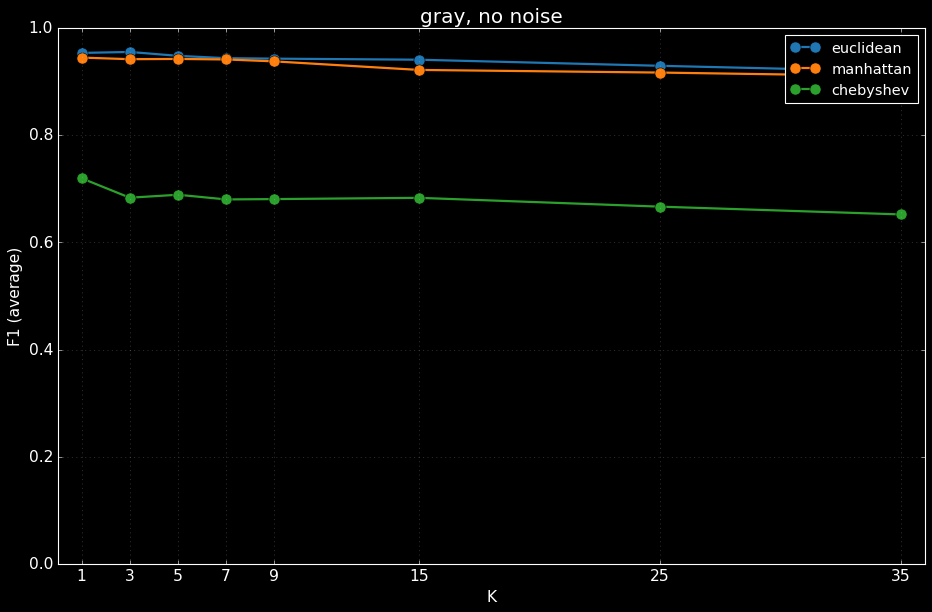

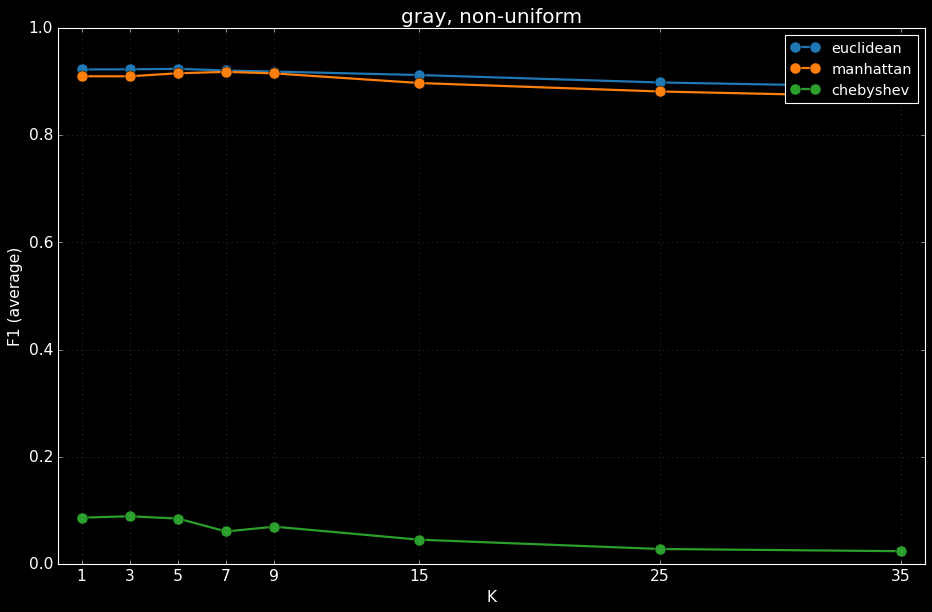

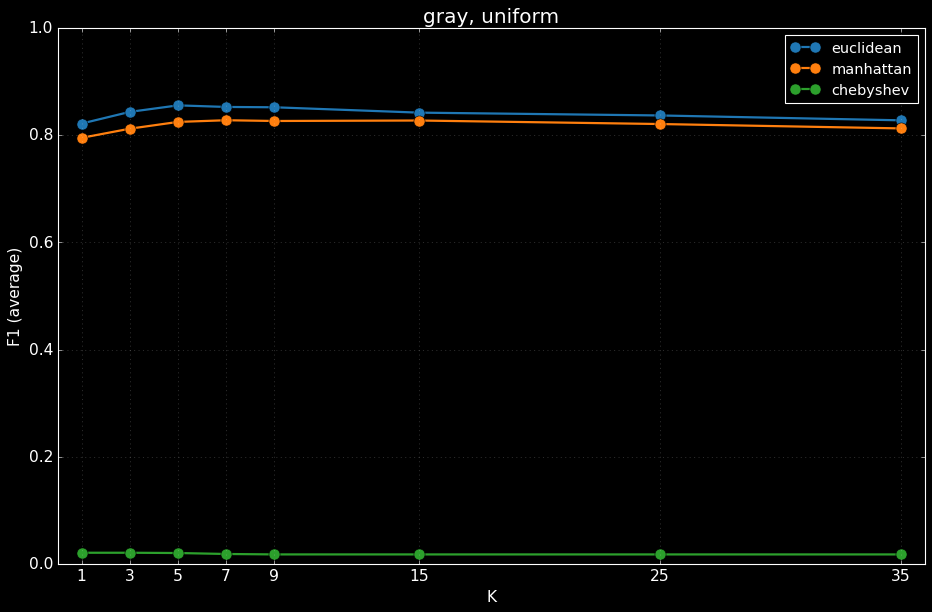

In [1000]:
from collections import defaultdict

colors = {
    "euclidean": "tab:blue",
    "manhattan": "tab:orange",
    "chebyshev": "tab:green",
}

groups = defaultdict(lambda: defaultdict(list))

for row in json_data:
    key = (row["type"], row["noise"])
    groups[key][row["metric"]].append(
        (row["k"], row["f1_avg"])
    )

for (img_type, noise), metrics in sorted(groups.items()):
    plt.figure(figsize=(12, 8))

    for metric, values in metrics.items():
        values = sorted(values, key=lambda x: x[0])

        k_values = [x[0] for x in values]
        f1_values = [x[1] for x in values]

        plt.plot(
            k_values,
            f1_values,
            marker="o",
            markersize=10,
            label=metric,
            linewidth=2,
            color=colors[metric]
        )

    # Человекочитаемое название шума
    noise_name = noise if noise else "no noise"

    plt.title(
        f"{img_type}, {noise_name}"
    )
    plt.xlabel("K")
    plt.ylabel("F1 (average)")
    plt.xticks(sorted(set(row["k"] for row in json_data)))

    plt.xlim(0, 36)

    plt.ylim(0, 1)
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()

    plt.show()

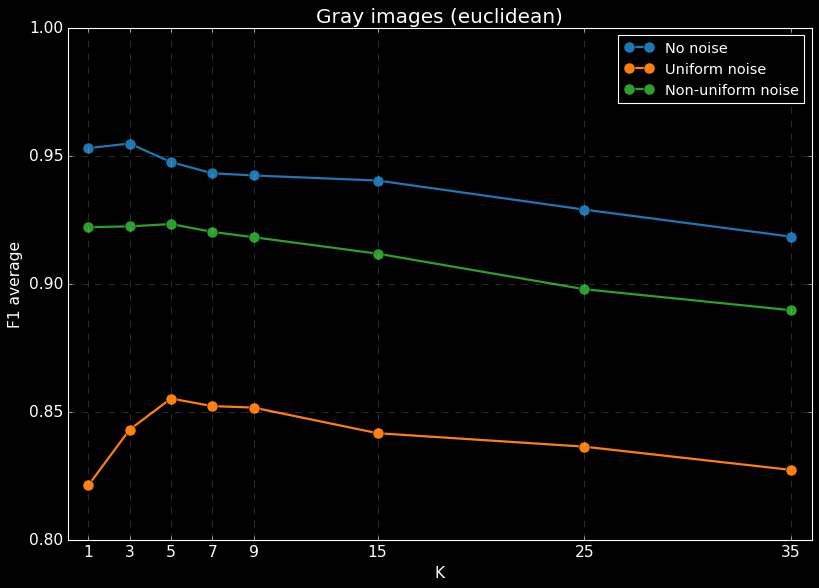

In [1007]:
groups = defaultdict(list)

for row in json_data:
    if row["type"] == "gray" and row["metric"] == "euclidean":
        groups[row["noise"]].append(
            (row["k"], row["f1_avg"])
        )

noise_names = {
    "": "No noise",
    "uniform": "Uniform noise",
    "non-uniform": "Non-uniform noise",
}

colors = {
    "": "#1f77b4",
    "uniform": "#ff7f0e",
    "non-uniform": "#2ca02c",
}

plt.figure(figsize=(12, 8))

for noise, values in groups.items():
    values = sorted(values, key=lambda x: x[0])

    k_values = [x[0] for x in values]
    f1_values = [x[1] for x in values]

    plt.plot(
        k_values,
        f1_values,
        marker="o",
        markersize=10,
        linewidth=2,
        label=noise_names[noise],
        color=colors[noise]
    )

plt.title(
    "Gray images (euclidean)",
)

plt.xlabel("K")
plt.ylabel("F1 average")

plt.xticks(
    [1, 3, 5, 7, 9, 15, 25, 35],
)

plt.grid(
    True,
    alpha=0.3,
    linestyle="--"
)

plt.xlim(0, 36)
plt.ylim(0.8, 1)
plt.legend()

plt.show()

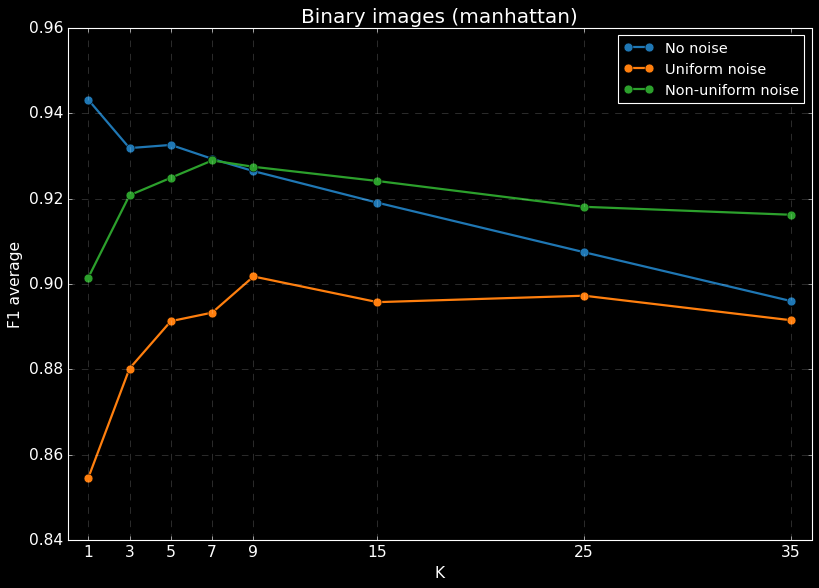

In [1008]:
groups = defaultdict(list)

for row in json_data:
    if row["type"] == "bin" and row["metric"] == "manhattan":
        groups[row["noise"]].append(
            (row["k"], row["f1_avg"])
        )

noise_names = {
    "": "No noise",
    "uniform": "Uniform noise",
    "non-uniform": "Non-uniform noise",
}

colors = {
    "": "#1f77b4",
    "uniform": "#ff7f0e",
    "non-uniform": "#2ca02c",
}

plt.figure(figsize=(12, 8))

for noise, values in groups.items():
    values = sorted(values, key=lambda x: x[0])

    k_values = [x[0] for x in values]
    f1_values = [x[1] for x in values]

    plt.plot(
        k_values,
        f1_values,
        marker="o",
        markersize=8,
        linewidth=2,
        label=noise_names[noise],
        color=colors[noise]
    )

plt.title(
    "Binary images (manhattan)",
)

plt.xlabel("K")
plt.ylabel("F1 average")

plt.xticks(
    [1, 3, 5, 7, 9, 15, 25, 35],
)
plt.yticks()

plt.xlim(0, 36)

plt.grid(
    True,
    alpha=0.3,
    linestyle="--"
)

plt.legend()

plt.show()